# Phase 6 — Model Evaluation & Selection for FD002
**Notebook:** `07b_Evaluation_FD002.ipynb` · **Project:** Intelligent Predictive Maintenance — RUL Estimation

Same procedure as FD001 (`04b_Evaluation_FD001`), in this exact order:

| Step | Uses | Purpose |
|---|---|---|
| 1. Reload all 4 saved models | `models/FD002/*` | Prove the saved bundles reproduce Phase 5 |
| 2. Fair CPU timing | validation points | Deployment runs on CPU |
| 3. Diagnostic plots | validation points | Actual vs predicted, residuals, error by RUL band |
| 4. **Select & freeze** the production model | validation only | Rule saved **before** the test set is opened |
| 5. **Official NASA test evaluation, once** | `test_FD002.txt` + `RUL_FD002.txt` | Unbiased estimate |

**Conventions:** `d = predicted − true` (d > 0 = **late** = dangerous). Validation uses the test-like cut points from Phase 3; primary metric = RMSE where true RUL ≤ cap. Test metrics are over **all test engines** at their last cycle, against the **true, uncapped** RUL.

⚙️ CPU is enough (about 3–6 minutes).

## Cell 1 — Setup

In [1]:
# Cell 1 — Setup
import os, sys, json, time, importlib
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW_DIR     = Path("/content/drive/MyDrive/CMAPSSData")
    PROJECT_DIR = Path("/content/drive/MyDrive/Predictive_Maintenance_RUL")
except ImportError:
    RAW_DIR     = Path(os.environ["CMAPSS_RAW_DIR"])
    PROJECT_DIR = Path(os.environ["PROJECT_DIR"])

FD, SEED = "FD002", 42
SRC_DIR    = PROJECT_DIR / "src"
MODEL_DIR  = PROJECT_DIR / "models" / FD
PROC_DIR   = PROJECT_DIR / "data" / "processed" / FD
FIG_DIR    = PROJECT_DIR / "reports" / "figures" / FD
RESULT_DIR = PROJECT_DIR / "reports" / "model_results" / FD
sys.path.insert(0, str(PROJECT_DIR))
sns.set_theme(style="whitegrid")

MODELS = ["Linear Regression", "Random Forest", "XGBoost", "LSTM"]
for folder in ["linear_regression", "random_forest", "xgboost", "lstm"]:
    assert (MODEL_DIR / folder / "metadata.json").exists(), f"{folder} missing → run 07_Model_Training_FD002 first"
assert (RESULT_DIR / "validation_comparison.csv").exists(), "Phase 5 results missing → run 07_Model_Training_FD002 first"
print("✅ Phase 5 models + results found")

✅ Phase 5 models + results found


## Cell 2 — Update `src/prediction.py`
The single "raw sensor history → RUL" path, used here and later by the FastAPI backend. This version adds two things while staying compatible with FD001:
1. It loads **either** preprocessor (single-regime `CMAPSSPreprocessor` or per-regime `RegimePreprocessor`) via `load_preprocessor`.
2. When the LSTM recipe includes rolling means (FD002/FD004), it computes them from the raw history before building the sequence.

Cell 3 re-checks that every saved model still reproduces its Phase 5 predictions through this file.

In [2]:
%%writefile {SRC_DIR}/prediction.py
"""
prediction.py — Load a saved model bundle and predict RUL from RAW engine history.

Why this file exists: evaluation (Phase 6), the FastAPI backend and the tests must all
turn raw sensor rows into a prediction in exactly the same way:
    raw rows -> saved preprocessing (validate + scale) -> saved feature recipe -> saved model
Everything is read from disk (models/FD002/...), nothing is re-fitted.
"""
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from src import feature_engineering as fe
from src.preprocessing import CMAPSSPreprocessor

try:                                    # regime-aware datasets (FD002 / FD004)
    from src.regime_preprocessing import load_preprocessor
except ImportError:                     # project without FD002/FD004 yet
    load_preprocessor = CMAPSSPreprocessor.load

MODEL_FOLDERS = {"Linear Regression": "linear_regression", "Random Forest": "random_forest",
                 "XGBoost": "xgboost", "LSTM": "lstm"}


class RULPredictor:
    """One trained model + its preprocessing + its feature recipe, loaded from models/FD002/."""

    def __init__(self, dataset_dir, model_name: str, device: str = "cpu"):
        dataset_dir = Path(dataset_dir)
        self.name = model_name
        self.dir = dataset_dir / MODEL_FOLDERS[model_name]
        self.meta = json.loads((self.dir / "metadata.json").read_text())
        self.prep = load_preprocessor(dataset_dir / "preprocessing")     # single-regime or per-regime
        self.feat_cfg = json.loads((dataset_dir / "feature_config.json").read_text())
        self.cap = float(self.meta["rul_cap"])
        self.device = device
        self.base = self.feat_cfg["base_features"]
        if self.meta["input"] == "sequence":
            from src.model_training import load_lstm
            self.model, _ = load_lstm(self.dir, device)
            self.seq_len = int(self.meta["seq_len"])
            self.min_history = self.seq_len
            # LSTM inputs: plain sensors (FD001) or sensors + causal rolling means (FD002/FD004)
            self.seq_features = self.meta.get("features", self.base)
            self.seq_rolling_window = self.feat_cfg["lstm"].get("rolling_window")
        else:
            if self.meta["model_file"].endswith(".json"):          # XGBoost
                from xgboost import XGBRegressor
                self.model = XGBRegressor()
                self.model.load_model(self.dir / self.meta["model_file"])
                self.model.set_params(device=device)
                self.model.get_booster().set_param({"device": device})
            else:                                                   # scikit-learn
                self.model = joblib.load(self.dir / self.meta["model_file"])
            tab = self.feat_cfg["tabular"]
            self.window, self.include_cycle = tab["window"], tab["include_cycle"]
            self.feature_order = tab["feature_order"]
            self.min_history = 1

    # -------------------------------------------------------------- core
    def model_inputs(self, raw_df: pd.DataFrame, points: pd.DataFrame):
        """Raw history -> model-ready inputs for each (engine_id, cut_cycle) in `points`."""
        scaled = self.prep.transform(raw_df)                       # validates columns / NaN, then scales
        if self.meta["input"] == "sequence":
            if self.seq_rolling_window:
                scaled = fe.add_rolling_features(scaled, self.base, self.seq_rolling_window)
            return fe.sequences_at(scaled, self.seq_features, self.seq_len, points)
        feats, _ = fe.build_tabular(scaled, self.base, self.window, self.include_cycle)
        return fe.rows_at(feats, points)[self.feature_order]

    def predict_inputs(self, X) -> np.ndarray:
        """Model-ready inputs -> RUL predictions (clipped at 0)."""
        if self.meta["input"] == "sequence":
            from src.model_training import lstm_predict
            return lstm_predict(self.model, X, self.cap, self.device)
        return np.clip(self.model.predict(X), 0, None)

    def predict_at(self, raw_df: pd.DataFrame, points: pd.DataFrame) -> np.ndarray:
        return self.predict_inputs(self.model_inputs(raw_df, points))

    def predict_last(self, raw_df: pd.DataFrame) -> pd.DataFrame:
        """Predict at each engine's LAST observed cycle (what the official test set asks for)."""
        last = raw_df.groupby("engine_id")["cycle"].max().rename("cut_cycle").reset_index()
        short = last[last["cut_cycle"] < self.min_history]
        if len(short):
            raise ValueError(f"{self.name} needs >= {self.min_history} cycles; engines too short: "
                             f"{short.engine_id.tolist()}")
        last["predicted_rul"] = self.predict_at(raw_df, last)
        return last

Overwriting C:\Users\ishaan\AppData\Local\Temp\claude\2e673f959c1787e2\b883298c-70a8-4fd3-82c4-3152adc8c2ef\scratchpad\colabsim_run\Predictive_Maintenance_RUL\src/prediction.py


## Cell 3 — Reload every model from disk (CPU) and reproduce Phase 5

In [3]:
# Cell 3 — Load predictors and validation data
import src.data_loader as dl, src.preprocessing as pp, src.evaluation as ev
import src.feature_engineering as fe, src.model_training as mt, src.prediction as pr
for m in (dl, pp, ev, fe, mt, pr):
    importlib.reload(m)

split    = json.loads((PROC_DIR / "split.json").read_text())
val_cuts = pd.read_csv(PROC_DIR / "val_cut_points.csv")
p5_preds = pd.read_csv(RESULT_DIR / "validation_predictions.csv")
p5_table = pd.read_csv(RESULT_DIR / "validation_comparison.csv", index_col="Model")
d = dl.load_dataset(FD, RAW_DIR)
raw_val = d["train"][d["train"].engine_id.isin(split["val_engine_ids"])]
y_val = val_cuts["true_rul"].values
N_VAL = len(val_cuts)

predictors = {name: pr.RULPredictor(MODEL_DIR, name, device="cpu") for name in MODELS}
CAP = predictors["XGBoost"].cap
C = int(CAP)
val_pred, check = {}, []
for name, p in predictors.items():
    val_pred[name] = p.predict_at(raw_val, val_cuts)
    diff = np.abs(val_pred[name] - p5_preds[name].values).max()
    check.append({"Model": name, "max |CPU − Phase 5| (cycles)": round(float(diff), 4)})
display(pd.DataFrame(check).set_index("Model"))
assert all(c["max |CPU − Phase 5| (cycles)"] < 1.0 for c in check), "Saved model does not reproduce Phase 5!"
print(f"✅ All 4 saved models reproduce their Phase 5 validation predictions ({N_VAL} points)")

,max |CPU − Phase 5| (cycles)
Model,
Linear Regression,0.0
Random Forest,0.0
XGBoost,0.0
LSTM,0.0


✅ All 4 saved models reproduce their Phase 5 validation predictions (520 points)


## Cell 4 — Validation table with fair CPU timing
- **Model only:** features ready → time to score all validation points.
- **End-to-end:** raw rows → scaling → features/sequences → prediction (closer to one API request).

In [4]:
# Cell 4 — Metrics + CPU timing + size
rows = []
for name, p in predictors.items():
    X = p.model_inputs(raw_val, val_cuts)
    _, t_model = mt.time_inference(lambda: p.predict_inputs(X), n_repeats=5)
    _, t_e2e = mt.time_inference(lambda: p.predict_at(raw_val, val_cuts), n_repeats=3)
    size_mb = sum(f.stat().st_size for f in p.dir.iterdir() if f.name != "tuning_best_checkpoint.pt") / 1e6
    m = mt.point_metrics(y_val, val_pred[name], CAP)
    rows.append({"Model": name, f"MAE (≤{C})": m["MAE_le_cap"], f"RMSE (≤{C})": m["RMSE_le_cap"],
                 f"NASA (≤{C})": m["NASA_le_cap"], f"Bias (≤{C})": m["bias_le_cap"], "RMSE (all points)": m["RMSE_all"],
                 "Train time (s)": p5_table.loc[name, "Train time (s)"],
                 "Tuning time (s)": p5_table.loc[name, "Tuning time (s)"],
                 "CPU inference, model only (ms)": t_model * 1000,
                 "CPU end-to-end (ms)": t_e2e * 1000, "Model size (MB)": size_mb})
val_table = pd.DataFrame(rows).set_index("Model")
val_table.to_csv(RESULT_DIR / "validation_comparison_cpu.csv")
RM, NA, BI = f"RMSE (≤{C})", f"NASA (≤{C})", f"Bias (≤{C})"
display(val_table.round(2))

,MAE (≤125),RMSE (≤125),NASA (≤125),Bias (≤125),RMSE (all points),Train time (s),Tuning time (s),"CPU inference, model only (ms)",CPU end-to-end (ms),Model size (MB)
Model,,,,,,,,,,
Linear Regression,16.40,20.30,4471.44,10.81,34.39,0.06,0.00,0.46,230.38,0.00
Random Forest,7.49,10.86,873.37,2.85,29.12,9.69,46.55,28.22,260.86,13.38
XGBoost,7.94,11.25,904.44,3.14,28.92,1.99,11.27,3.02,271.09,0.97
LSTM,12.92,17.26,3210.78,9.07,31.34,9.64,114.19,9.03,393.60,0.35


---
## Cell 5 — Diagnostic plots on validation

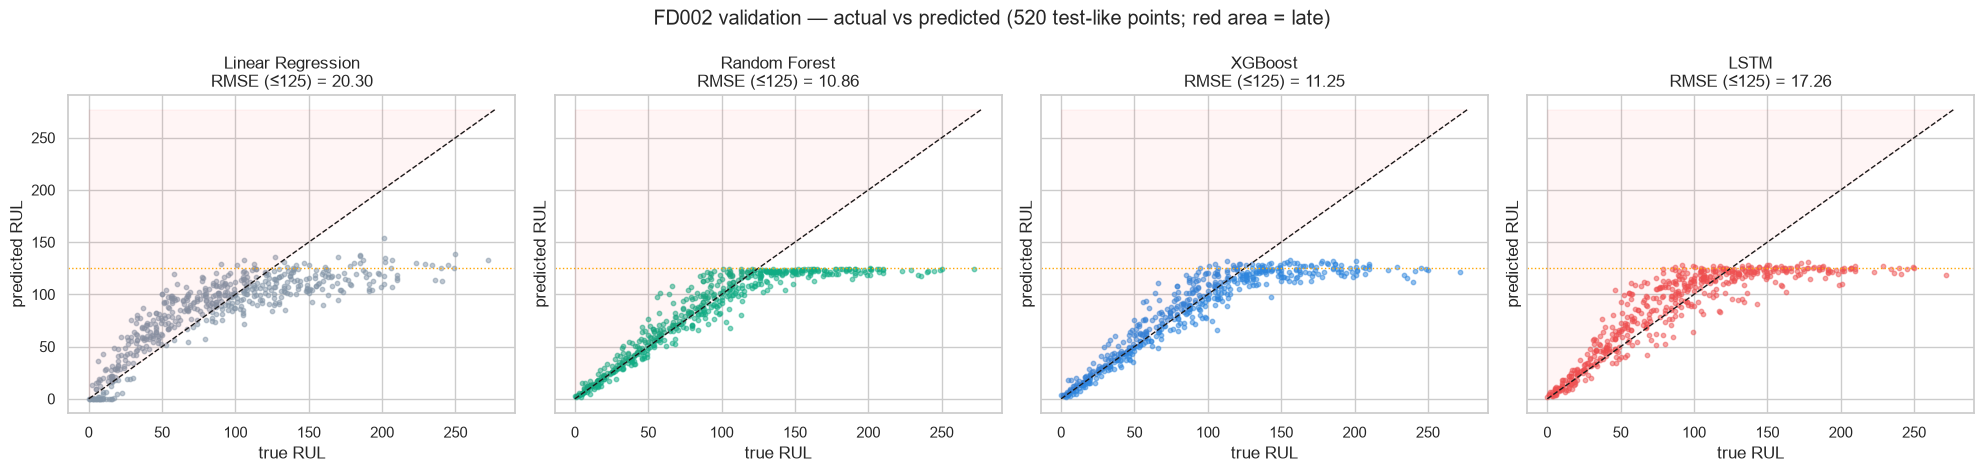

In [5]:
# Cell 5a — Actual vs predicted
colors = {"Linear Regression": "#8395a7", "Random Forest": "#10ac84", "XGBoost": "#2e86de", "LSTM": "#ee5253"}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharex=True, sharey=True)
lim = y_val.max() + 5
for ax, name in zip(axes, MODELS):
    ax.scatter(y_val, val_pred[name], s=10, alpha=0.5, color=colors[name])
    ax.plot([0, lim], [0, lim], "k--", lw=1); ax.axhline(CAP, color="orange", ls=":", lw=1)
    ax.fill_between([0, lim], [0, lim], [lim, lim], color="red", alpha=0.04)
    ax.set(title=f"{name}\n{RM} = {val_table.loc[name, RM]:.2f}", xlabel="true RUL", ylabel="predicted RUL")
fig.suptitle(f"{FD} validation — actual vs predicted ({N_VAL} test-like points; red area = late)")
fig.tight_layout(); fig.savefig(FIG_DIR / "eval_actual_vs_predicted_val.png", dpi=150, bbox_inches="tight"); plt.show()

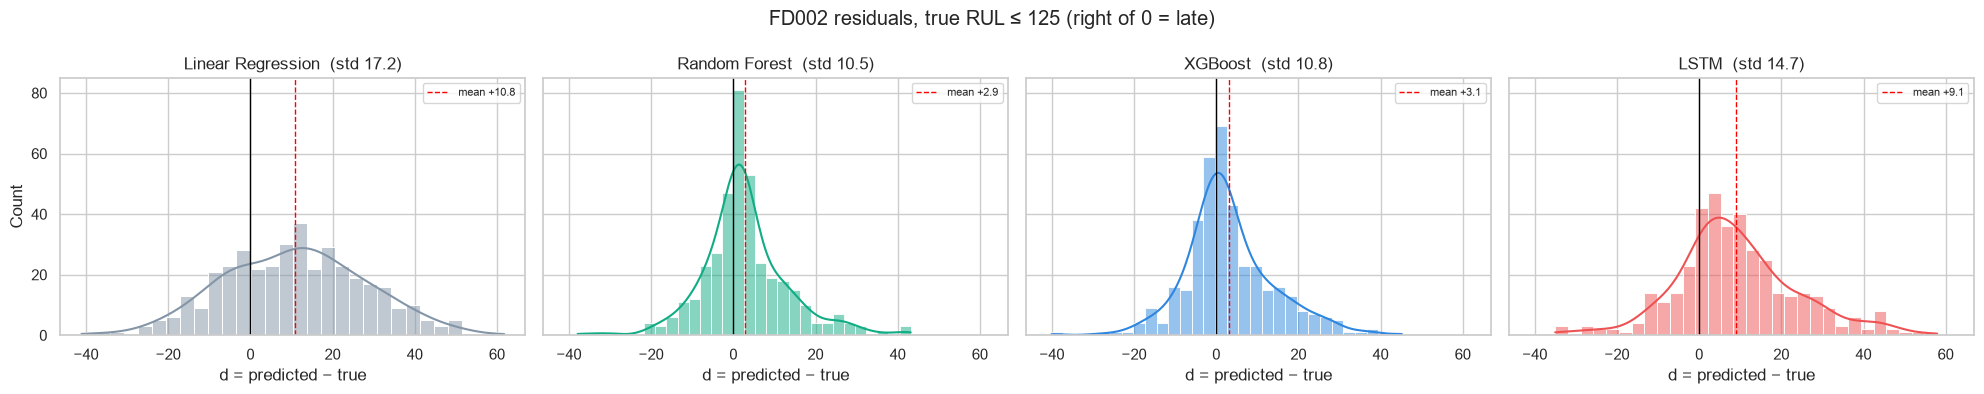

In [6]:
# Cell 5b — Residuals (true RUL ≤ cap)
mask = y_val <= CAP
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharex=True, sharey=True)
for ax, name in zip(axes, MODELS):
    res = val_pred[name][mask] - y_val[mask]
    sns.histplot(res, bins=30, ax=ax, color=colors[name], kde=True)
    ax.axvline(0, color="black", lw=1); ax.axvline(res.mean(), color="red", ls="--", lw=1, label=f"mean {res.mean():+.1f}")
    ax.set(title=f"{name}  (std {res.std():.1f})", xlabel="d = predicted − true"); ax.legend(fontsize=8)
fig.suptitle(f"{FD} residuals, true RUL ≤ {C} (right of 0 = late)")
fig.tight_layout(); fig.savefig(FIG_DIR / "eval_residuals_val.png", dpi=150, bbox_inches="tight"); plt.show()

,n points,Linear Regression,Random Forest,XGBoost,LSTM
0–25,76,12.7,3.7,4.0,4.7
26–50,78,26.0,8.1,8.4,16.0
51–75,69,27.9,13.1,13.7,25.1
76–100,90,15.9,13.9,14.5,20.5
101–125,69,15.3,11.9,11.9,12.5
>125,138,57.6,53.6,52.9,53.6


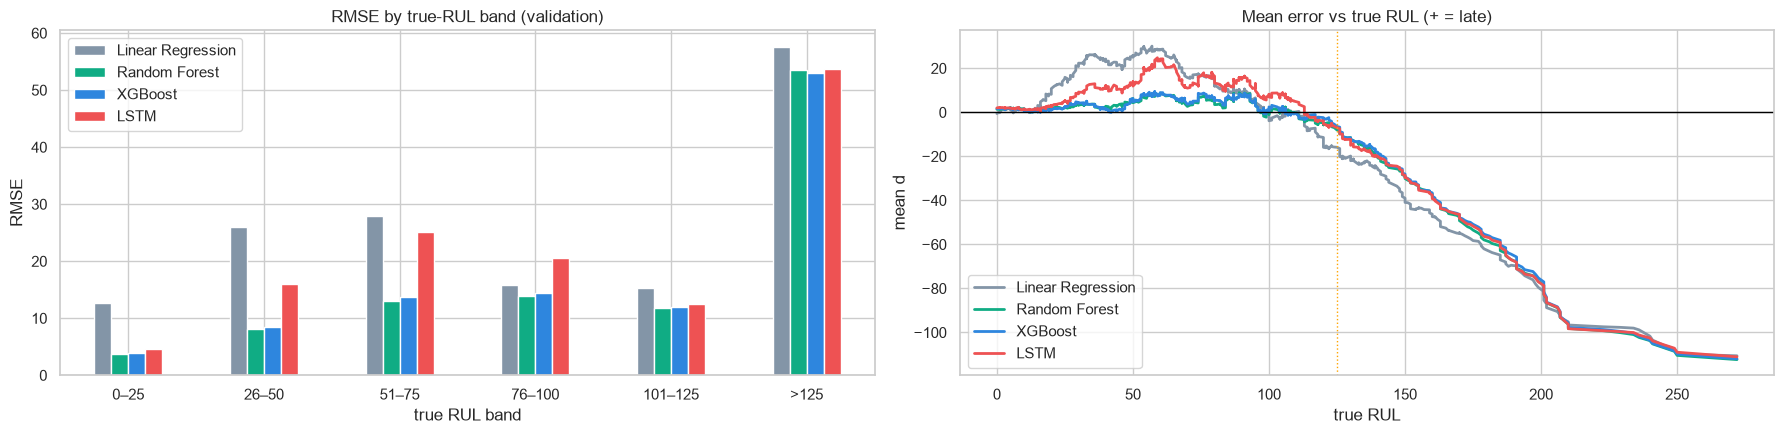

In [7]:
# Cell 5c — Error by RUL band + error vs true RUL
bands = pd.cut(y_val, [-1, 25, 50, 75, 100, 125, 1000], labels=["0–25", "26–50", "51–75", "76–100", "101–125", ">125"])
band_tbl = pd.DataFrame({name: pd.Series(val_pred[name] - y_val).groupby(bands, observed=True)
                         .apply(lambda r: float(np.sqrt(np.mean(r ** 2)))) for name in MODELS})
band_tbl.insert(0, "n points", pd.Series(bands).value_counts().reindex(band_tbl.index).values)
band_tbl.to_csv(RESULT_DIR / "validation_rmse_by_band.csv")
display(band_tbl.round(1))
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
band_tbl[MODELS].plot.bar(ax=axes[0], color=[colors[m] for m in MODELS], rot=0)
axes[0].set(title="RMSE by true-RUL band (validation)", xlabel="true RUL band", ylabel="RMSE")
order = np.argsort(y_val)
for name in MODELS:
    err = (val_pred[name] - y_val)[order]
    axes[1].plot(y_val[order], pd.Series(err).rolling(25, center=True, min_periods=8).mean(), color=colors[name], label=name, lw=2)
axes[1].axhline(0, color="black", lw=1); axes[1].axvline(CAP, color="orange", ls=":", lw=1)
axes[1].set(title="Mean error vs true RUL (+ = late)", xlabel="true RUL", ylabel="mean d"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eval_error_by_band_val.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading these plots** (same logic as FD001):
- **Above the cap, every model turns early (negative error).** A capped model can't predict more than the cap, which is the accepted Phase 3 trade-off ("≥ cap = healthy").
- **The 0–25 band** (near failure) should have the smallest errors.
- **A late bump in the middle bands** is the main safety concern to watch for.

---
## Cell 6 — Select and FREEZE the production model (validation only)
**Rule (same as FD001, fixed before the test set is opened):**
1. Lowest validation RMSE (true RUL ≤ cap).
2. Models within **0.5 RMSE** of the best are tied.
3. Among tied models: lowest NASA score, then smaller file, then faster CPU inference.

Written to `models/FD002/selected_model.json`, and **never overwritten** once it exists.

In [8]:
# Cell 6 — Apply the rule and freeze
SEL_FILE, TIE_MARGIN = MODEL_DIR / "selected_model.json", 0.5
ranked = val_table.sort_values(RM)
best_rmse = ranked[RM].iloc[0]
tied = ranked[ranked[RM] <= best_rmse + TIE_MARGIN]
chosen = tied.sort_values([NA, "Model size (MB)", "CPU inference, model only (ms)"]).index[0]
display(ranked[[RM, NA, BI, "Model size (MB)"]].round(2))
print(f"Within {TIE_MARGIN} of best ({best_rmse:.2f}): {list(tied.index)} → chosen: {chosen}")
if SEL_FILE.exists():
    frozen = json.loads(SEL_FILE.read_text())
    print(f"🔒 Already frozen on {frozen['frozen_at_utc']}: {frozen['selected_model']} (not overwritten)")
    SELECTED = frozen["selected_model"]
else:
    SELECTED = chosen
    SEL_FILE.write_text(json.dumps({
        "dataset": FD, "selected_model": SELECTED, "model_dir": pr.MODEL_FOLDERS[SELECTED],
        "rule": f"min validation RMSE(true RUL<={C}); ties within {TIE_MARGIN} broken by NASA score, then size, then speed",
        "validation_metrics": {k: float(v) for k, v in val_table.loc[SELECTED].items()},
        "candidates": {m: {"RMSE_le_cap": float(val_table.loc[m, RM]), "NASA_le_cap": float(val_table.loc[m, NA])}
                       for m in MODELS},
        "frozen_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "test_set_seen_before_selection": False}, indent=2))
    print(f"🔒 Frozen: {SELECTED} → {SEL_FILE.name}")

,RMSE (≤125),NASA (≤125),Bias (≤125),Model size (MB)
Model,,,,
Random Forest,10.86,873.37,2.85,13.38
XGBoost,11.25,904.44,3.14,0.97
LSTM,17.26,3210.78,9.07,0.35
Linear Regression,20.30,4471.44,10.81,0.00


Within 0.5 of best (10.86): ['Random Forest', 'XGBoost'] → chosen: Random Forest
🔒 Frozen: Random Forest → selected_model.json


---
## Cell 7 — Official NASA test evaluation (run once)
Only now are `test_FD002.txt` and `RUL_FD002.txt` opened. The selected model's score is the headline. The other three are **reference only** (the dashboard comparison page needs them), and the selection above is already frozen.

In [9]:
# Cell 7 — Test evaluation
TEST_FILE = RESULT_DIR / "test_evaluation.json"
if TEST_FILE.exists():
    print(f"⚠️ Test set already evaluated on {json.loads(TEST_FILE.read_text())['evaluated_at_utc']}; re-display only.\n")
test_raw, rul_true = d["test"], d["rul"].set_index("engine_id")["true_rul"]
test_rows, test_preds = [], None
for name, p in predictors.items():
    out = p.predict_last(test_raw)
    y_t, yhat = rul_true.loc[out.engine_id].values, out["predicted_rul"].values
    test_rows.append({"Model": name, "Selected": "★" if name == SELECTED else "",
                      "MAE": ev.mae(y_t, yhat), "RMSE": ev.rmse(y_t, yhat), "NASA score": ev.nasa_score(y_t, yhat),
                      "Bias": float(np.mean(yhat - y_t)), f"RMSE (true ≤{C})": ev.rmse(y_t[y_t <= CAP], yhat[y_t <= CAP]),
                      "Late > 10 cycles (%)": float(np.mean(yhat - y_t > 10) * 100),
                      f"Validation RMSE (≤{C})": val_table.loc[name, RM]})
    if test_preds is None:
        test_preds = out[["engine_id", "cut_cycle"]].assign(true_rul=y_t)
    test_preds[name] = yhat
test_table = pd.DataFrame(test_rows).set_index("Model")
test_table.to_csv(RESULT_DIR / "test_results.csv")
test_preds.to_csv(RESULT_DIR / "test_predictions.csv", index=False)
print(f"Official {FD} test set: {len(test_preds)} engines, true RUL {rul_true.min()}–{rul_true.max()}")
display(test_table.round(2))
if not TEST_FILE.exists():
    sel = test_table.loc[SELECTED]
    TEST_FILE.write_text(json.dumps({
        "dataset": FD, "selected_model": SELECTED, "n_engines": int(len(test_preds)),
        "selected_model_test_metrics": {k: float(sel[k]) for k in ["MAE", "RMSE", "NASA score", "Bias", f"RMSE (true ≤{C})"]},
        "reference_models_test_rmse": {m: float(test_table.loc[m, "RMSE"]) for m in MODELS},
        "evaluated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "note": f"Reference models not used for selection; selection frozen in models/{FD}/selected_model.json"}, indent=2))
    print("Saved →", TEST_FILE.name)

Official FD002 test set: 259 engines, true RUL 6–194


,Selected,MAE,RMSE,NASA score,Bias,RMSE (true ≤125),Late > 10 cycles (%),Validation RMSE (≤125)
Model,,,,,,,,
Linear Regression,,22.11,29.64,10072.09,-5.46,17.69,35.14,20.30
Random Forest,★,14.74,23.19,3884.80,-7.31,11.37,12.74,10.86
XGBoost,,14.45,22.80,3966.42,-7.50,10.57,11.97,11.25
LSTM,,16.93,24.32,3934.50,-5.65,14.94,18.92,17.26


Saved → test_evaluation.json


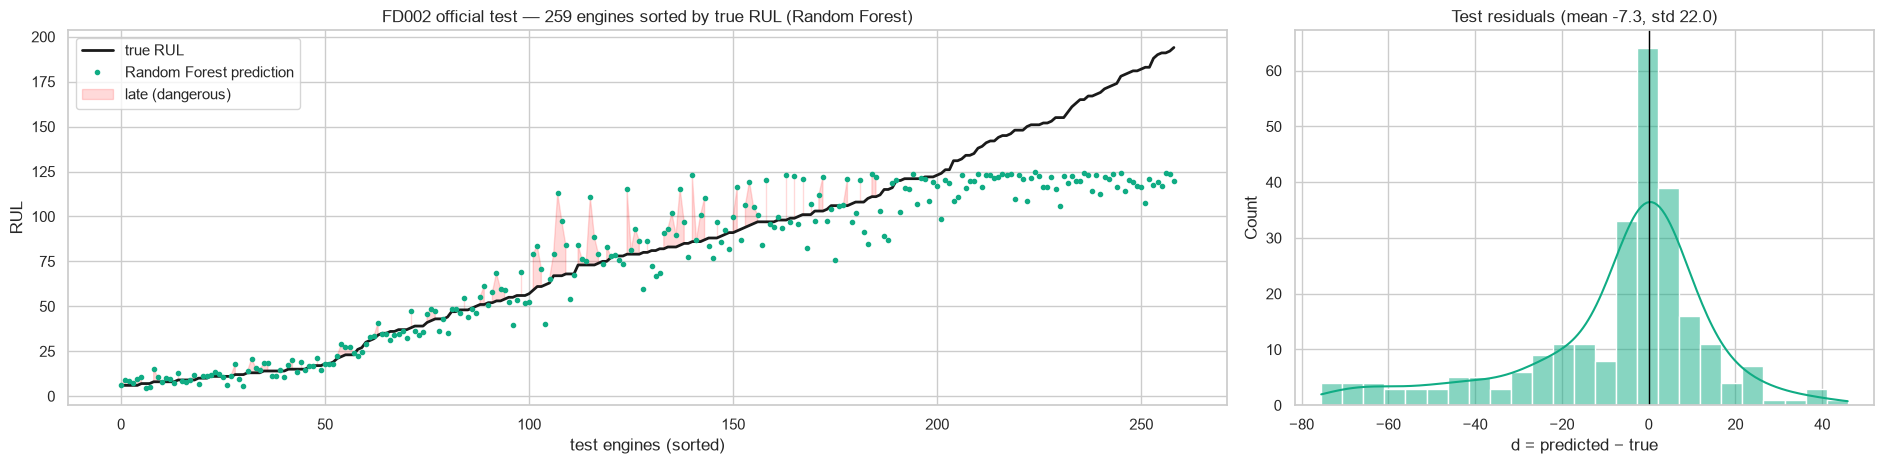

In [10]:
# Cell 7b — Test-set plots
order_t = test_preds.sort_values("true_rul").reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(19, 4.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(order_t.index, order_t.true_rul, "k-", lw=2, label="true RUL")
axes[0].plot(order_t.index, order_t[SELECTED], "o", ms=3, color=colors[SELECTED], label=f"{SELECTED} prediction")
axes[0].fill_between(order_t.index, order_t.true_rul, order_t[SELECTED], where=order_t[SELECTED] > order_t.true_rul,
                     color="red", alpha=0.15, label="late (dangerous)")
axes[0].set(title=f"{FD} official test — {len(order_t)} engines sorted by true RUL ({SELECTED})",
            xlabel="test engines (sorted)", ylabel="RUL"); axes[0].legend()
res = order_t[SELECTED] - order_t.true_rul
sns.histplot(res, bins=25, kde=True, ax=axes[1], color=colors[SELECTED]); axes[1].axvline(0, color="black", lw=1)
axes[1].set(title=f"Test residuals (mean {res.mean():+.1f}, std {res.std():.1f})", xlabel="d = predicted − true")
fig.tight_layout(); fig.savefig(FIG_DIR / "eval_test_selected_model.png", dpi=150, bbox_inches="tight"); plt.show()

## Cell 8 — Summary

In [11]:
# Cell 8 — Summary
sv, st = val_table.loc[SELECTED], test_table.loc[SELECTED]
print(f"{FD} production model: {SELECTED}")
print(f"  Validation ({N_VAL} points, true RUL ≤ {C}): RMSE {sv[RM]:.2f} | MAE {sv[f'MAE (≤{C})']:.2f}")
print(f"  Official test ({len(test_preds)} engines): RMSE {st['RMSE']:.2f} | MAE {st['MAE']:.2f} | "
      f"NASA {st['NASA score']:.0f} | bias {st['Bias']:+.1f} | late>10: {st['Late > 10 cycles (%)']:.0f}%")

FD002 production model: Random Forest
  Validation (520 points, true RUL ≤ 125): RMSE 10.86 | MAE 7.49
  Official test (259 engines): RMSE 23.19 | MAE 14.74 | NASA 3885 | bias -7.3 | late>10: 13%


## Reference results (full local CPU run)
**Selected (validation only): Random Forest.** Official test, 259 engines:

| Model | Validation RMSE (≤125) | Test MAE | Test RMSE (all) | Test RMSE (true ≤125) | NASA | Bias | Late > 10 |
|---|---:|---:|---:|---:|---:|---:|---:|
| Linear Regression | 20.30 | 22.11 | 29.64 | 17.69 | 10072 | -5.5 | 35% |
| **Random Forest ★** | 10.86 | 14.74 | 23.19 | 11.37 | 3885 | -7.3 | 13% |
| XGBoost | 11.25 | 14.45 | 22.80 | 10.57 | 3966 | -7.5 | 12% |
| LSTM | 17.26 | 16.93 | 24.32 | 14.94 | 3935 | -5.6 | 19% |

**Interpretation:**
- For engines with true RUL ≤ 125, the selected model's test RMSE (**11.37**) is close to its validation RMSE (10.86). So the validation protocol gave an honest estimate.
- The **overall** test RMSE (23.19) is higher because it includes test engines whose true RUL is above the cap. A capped model predicts about 125 ("healthy") for them, which is the accepted trade-off from Phase 3.
- XGBoost is slightly better on the test set (true ≤ cap). That does **not** change the frozen selection, because choosing by test results would bias the reported score.

## ✅ Verify
1. Cell 3: all differences small (≈0 for LR/RF; < 1 cycle for GPU-trained XGBoost/LSTM).
2. Cell 6: `🔒 Frozen: …`. Cell 7: the table with ★ and `test_evaluation.json` saved.

**Next:** FD003 (`08_EDA_FD003`): one operating condition but **two fault modes**.